# Diabetes Detection Agent

Predicts diabetes risk two ways and lets an agent explain the results:

1. **Random Forest** trained on the Pima Indians Diabetes dataset
2. **Memory-based (ACT-R style)**: find similar past patients; if 60% or more were diabetic, predict diabetic

The agent checks the input, calls the tool, compares both results, and adds a disclaimer.

In [3]:
%pip install -r ../requirements.txt

  Using cached openai_agents-0.24.0-py3-none-any.whl.metadata (13 kB)
  Using cached scikit_learn-1.9.1-cp312-cp312-macosx_12_0_arm64.whl.metadata (9.3 kB)
  Using cached mcp-2.3.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached pyjwt-2.15.1-py3-none-any.whl.metadata (3.5 kB)
  Using cached urllib3-2.8.0-py3-none-any.whl.metadata (7.4 kB)
  Using cached mcp_types-2.3.0-py3-none-any.whl.metadata (1.9 kB)
  Using cached opentelemetry_api-1.45.1-py3-none-any.whl.metadata (1.4 kB)
  Using cached sse_starlette-3.5.0-py3-none-any.whl.metadata (15 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
  Using cached cryptography-50.0.2-cp311-abi3-macosx_11_0_arm64.whl.metadata (4.4 kB)
Using cached openai_agents-0.24.0-py3-none-any.whl (1.2 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 14.3 MB/s  0:00:00
Using cached mcp-2.3.0-py3-

In [4]:
import pandas as pd
from agents import Agent, Runner, function_tool
from dotenv import load_dotenv
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

load_dotenv();

## 1. Load data

In [5]:
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
COLS = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin",
        "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"]

df = pd.read_csv(URL, names=COLS)
print(df.shape)
df.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 2. Random Forest

In [6]:
X, y = df[COLS[:-1]], df["Outcome"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=67, stratify=y)
rf = RandomForestClassifier(n_estimators=200, random_state=67).fit(X_tr, y_tr)
print(f"Test accuracy: {rf.score(X_te, y_te):.0%}")

Test accuracy: 75%


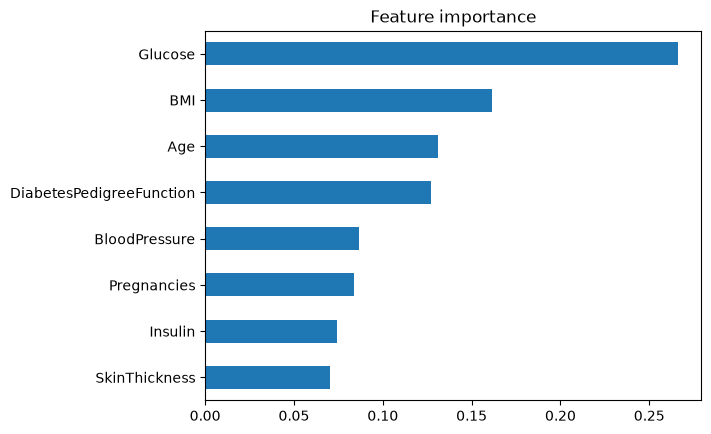

In [7]:
pd.Series(rf.feature_importances_, index=COLS[:-1]).sort_values().plot.barh(title="Feature importance");

## 3. Memory-based prediction (ACT-R style)

A past patient is "similar" if glucose is within 15, BMI within 3, and age within 5. Fewer than 5 similar patients means low confidence.

In [8]:
def memory_predict(glucose, bmi, age):
    m = df[(df.Glucose.sub(glucose).abs() <= 15) & (df.BMI.sub(bmi).abs() <= 3) & (df.Age.sub(age).abs() <= 5)]
    if m.empty:
        return {"matches": 0, "prediction": "unknown", "confidence": "none"}
    share = float(m.Outcome.mean())
    return {"matches": len(m), "diabetic_share": round(share, 2),
            "prediction": "diabetic" if share >= 0.6 else "not diabetic",
            "confidence": "low" if len(m) < 5 else "normal"}

memory_predict(148, 33.6, 50)

{'matches': 10,
 'diabetic_share': 0.9,
 'prediction': 'diabetic',
 'confidence': 'normal'}

## 4. Tool and agent

In [9]:
@function_tool
def assess_risk(pregnancies: int, glucose: float, blood_pressure: float, skin_thickness: float,
                insulin: float, bmi: float, pedigree: float, age: int) -> dict:
    """Run the Random Forest model and the memory-based model on one patient."""
    row = pd.DataFrame([[pregnancies, glucose, blood_pressure, skin_thickness, insulin, bmi, pedigree, age]],
                       columns=COLS[:-1])
    p = float(rf.predict_proba(row)[0][1])
    return {"random_forest": {"diabetic_probability": round(p, 2),
                              "prediction": "diabetic" if p >= 0.5 else "not diabetic"},
            "memory_based": memory_predict(glucose, bmi, age)}


agent = Agent(
    name="Diabetes Risk Agent",
    model="gpt-4o-mini",
    tools=[assess_risk],
    instructions=(
        "Blood pressure here is diastolic (the lower number), so 60-90 is normal. "
        "Insulin and skin thickness can be 0 because they were often not measured. "
        "You explain diabetes risk. If glucose, BMI, blood pressure, or age is 0 or impossible, "
        "ask the user for a valid value and do not call the tool. Otherwise call assess_risk. "
        "Explain both results side by side in plain words. If the memory-based confidence is low or none, say so. "
        "If the two models disagree, say that clearly. End with: 'This is not medical advice. Please see a doctor.'"
    ),
)

## 5. Tests

In [10]:
tests = {
    "D1 high risk": "Pregnancies 6, glucose 148, blood pressure 72, skin 35, insulin 0, BMI 33.6, pedigree 0.627, age 50",
    "D2 low risk": "Pregnancies 1, glucose 85, blood pressure 66, skin 29, insulin 0, BMI 26.6, pedigree 0.351, age 31",
    "D3 no similar cases": "Pregnancies 2, glucose 250, blood pressure 90, skin 40, insulin 300, BMI 60, pedigree 1.2, age 90",
    "D4 invalid BMI": "Pregnancies 1, glucose 120, blood pressure 70, skin 20, insulin 80, BMI 0, pedigree 0.5, age 35",
}

for name, text in tests.items():
    result = await Runner.run(agent, text)
    print(f"=== {name} ===\n{result.final_output}\n")

=== D1 high risk ===
Based on the assessments:

### Random Forest Model
- **Diabetic Probability:** 85%
- **Prediction:** Diabetic

### Memory-Based Model
- **Diabetic Share of Matches:** 90%
- **Prediction:** Diabetic
- **Confidence Level:** Normal

### Summary
Both models predict that you are likely to be diabetic, with the Random Forest model indicating an 85% probability and the Memory-Based model reflecting a 90% agreement among similar cases. The confidence in the Memory-Based model is considered normal.

Since both models agree on the prediction of diabetes, it reinforces the reliability of the result.

This is not medical advice. Please see a doctor.

=== D2 low risk ===
It looks like the blood pressure and insulin values you've provided could be concerning. Let's clarify:

1. **Blood Pressure**: A value of 66 is not a typical value for blood pressure. Normal blood pressure is generally around 90-120 for the systolic (upper number) and 60-80 for the diastolic (lower number). Wo